# **BÀI TẬP LỚN KẾT THÚC HỌC PHẦN: HỌC MÁY CƠ BẢN**
## **PROJECT 13: ĐÁNH GIÁ NGUY CƠ HỦY ĐẶT PHÒNG TẠI THỜI ĐIỂM ĐẶT (AT THE TIME OF BOOKING)**
* **Giảng viên hướng dẫn:** PGS.TS. Nguyễn Văn Hậu
* **Lớp học phần:** 101230.1 / 12523W.1
* **Sinh viên thực hiện:**
  1. Cao Văn Hiến - MSV: 10123115
  2. Lê Hồng Đăng - MSV: 10123097
* **Thuật toán trọng tâm:** Bài 5 — Hồi quy Logistic: Phân loại bằng xác suất (Supervised Binary Classification)
* **Tập dữ liệu:** Hotel Booking Demand Dataset (119.390 bản ghi, CC BY 4.0)

# **Bước 1 — Khởi tạo môi trường và nạp thư viện**

In [ ]:
# ==========================================
# BƯỚC 1: KHỞI TẠO MÔI TRƯỜNG VÀ NẠP THƯ VIỆN
# ==========================================
import os
import time
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, brier_score_loss, roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)
from sklearn.calibration import calibration_curve

warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Đã nạp đầy đủ thư viện phân tích học máy thành công.")

Đã nạp đầy đủ thư viện phân tích học máy thành công.


Bước 2 — Tải dữ liệu và kiểm tra thuộc tính ban đầu

In [ ]:
# ==========================================
# BƯỚC 2: TẢI DỮ LIỆU VÀ KHÁM PHÁ BAN ĐẦU
# ==========================================
DATA_URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"
print("Đang tải dữ liệu gốc từ kho lưu trữ...")
df_raw = pd.read_csv(DATA_URL)

print("Kích thước dữ liệu gốc:", df_raw.shape)
print("\nDanh sách 32 cột dữ liệu ban đầu:")
print(df_raw.columns.tolist())
display(df_raw.head())

# Kiểm tra phân bố nhãn mục tiêu is_canceled
print("\n=== PHÂN BỐ BIẾN MỤC TIÊU (is_canceled) ===")
print("Số lượng bản ghi:")
print(df_raw['is_canceled'].value_counts())
print("\nTỷ lệ phần trăm:")
print((df_raw['is_canceled'].value_counts(normalize=True) * 100).round(2).astype(str) + '%')

Đang tải dữ liệu gốc từ kho lưu trữ...
Kích thước dữ liệu gốc: (119390, 32)

Danh sách 32 cột dữ liệu ban đầu:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



=== PHÂN BỐ BIẾN MỤC TIÊU (is_canceled) ===
Số lượng bản ghi:
is_canceled
0    75166
1    44224
Name: count, dtype: int64

Tỷ lệ phần trăm:
is_canceled
0    62.96%
1    37.04%
Name: proportion, dtype: object


# **Bước 3 — Chống rò rỉ dữ liệu (Data Leakage) & Làm sạch tại thời điểm đặt**

In [ ]:
# ==============================================================================
# BƯỚC 3: PHÂN TÍCH VÀ LOẠI BỎ TRIỆT ĐỂ RÒ RỈ DỮ LIỆU (ANTI-DATA LEAKAGE)
# ==============================================================================
# 5 biến phát sinh SAU thời điểm đặt phòng bắt buộc phải loại bỏ:
LEAKAGE_COLS = [
    'reservation_status',        # Trạng thái cuối cùng (đã hủy/check-out) - nhìn trước nhãn!
    'reservation_status_date',   # Ngày cập nhật trạng thái cuối cùng
    'assigned_room_type',        # Phòng thực tế lễ tân xếp khi khách đến nhận phòng
    'booking_changes',           # Số lần sửa đổi đặt phòng phát sinh trong thời gian chờ
    'days_in_waiting_list'       # Số ngày nằm trong danh sách chờ trước khi xác nhận
]
print(f"Loại bỏ 5 biến rò rỉ thông tin sau thời điểm đặt: {LEAKAGE_COLS}")
df_clean = df_raw.drop(columns=LEAKAGE_COLS)

# 1. Lọc bỏ các dòng bất hợp lý (Tổng khách adults + children + babies = 0)
initial_len = len(df_clean)
df_clean = df_clean[df_clean[['adults', 'children', 'babies']].sum(axis=1) > 0]
print(f"Đã loại {initial_len - len(df_clean)} đơn phòng có tổng số khách bằng 0.")

# 2. Xử lý giá trị khuyết thiếu (Missing Values)
df_clean['children'] = df_clean['children'].fillna(0)
df_clean['country'] = df_clean['country'].fillna('Unknown')

# 3. Kỹ thuật đặc trưng: Biến đổi cột agent và company thành biến cờ nhị phân (có/không có đại lý/công ty)
df_clean['has_agent'] = df_clean['agent'].notnull().astype(int)
df_clean['has_company'] = df_clean['company'].notnull().astype(int)
df_clean = df_clean.drop(columns=['agent', 'company'])

# Xử lý giá trị âm bất thường của tiền phòng adr (nếu có)
df_clean = df_clean[df_clean['adr'] >= 0]

print("Kích thước dữ liệu sạch hợp lệ tại thời điểm đặt:", df_clean.shape)

Loại bỏ 5 biến rò rỉ thông tin sau thời điểm đặt: ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'booking_changes', 'days_in_waiting_list']
Đã loại 180 đơn phòng có tổng số khách bằng 0.
Kích thước dữ liệu sạch hợp lệ tại thời điểm đặt: (119209, 27)


# **Bước 4 — Trích xuất miền dữ liệu thực tế (Domain Bounds) từ tập dữ liệu**

In [ ]:
# ==============================================================================
# BƯỚC 4: TRÍCH XUẤT MIỀN GIÁ TRỊ THỰC TẾ TRONG DATASET (DATA DOMAIN BOUNDS)
# ==============================================================================
# Danh sách 17 biến số thực (Numerical Features)
NUM_COLS = [
    'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month',
    'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies',
    'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled',
    'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'has_agent', 'has_company'
]

# Danh sách 9 biến phân loại (Categorical Features)
CAT_COLS = [
    'hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
    'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type'
]

domain_bounds = {"numerical": {}, "categorical": {}}

for col in NUM_COLS:
    domain_bounds["numerical"][col] = {
        "min": float(df_clean[col].min()),
        "p01": float(df_clean[col].quantile(0.01)),
        "median": float(df_clean[col].median()),
        "mean": float(round(df_clean[col].mean(), 4)),
        "std": float(round(df_clean[col].std(), 4)),
        "p99": float(df_clean[col].quantile(0.99)),
        "max": float(df_clean[col].max())
    }

for col in CAT_COLS:
    domain_bounds["categorical"][col] = df_clean[col].unique().tolist()

# Hiển thị bảng kiểm chứng miền giá trị chuẩn xác của Dataset
bounds_df = pd.DataFrame(domain_bounds["numerical"]).T
print("=== MIỀN GIÁ TRỊ THỰC TẾ TRONG BỘ DỮ LIỆU HOTEL BOOKING (CHỐT CHẶN OOD) ===")
display(bounds_df[['min', 'p01', 'median', 'p99', 'max']])

=== MIỀN GIÁ TRỊ THỰC TẾ TRONG BỘ DỮ LIỆU HOTEL BOOKING (CHỐT CHẶN OOD) ===


,min,p01,median,p99,max
lead_time,0.0,0.0,69.00,444.0,737.0
arrival_date_year,2015.0,2015.0,2016.00,2017.0,2017.0
arrival_date_week_number,1.0,2.0,28.00,53.0,53.0
arrival_date_day_of_month,1.0,1.0,16.00,31.0,31.0
stays_in_weekend_nights,0.0,0.0,1.00,4.0,19.0
stays_in_week_nights,0.0,0.0,2.00,10.0,50.0
adults,0.0,1.0,2.00,3.0,55.0
children,0.0,0.0,0.00,2.0,10.0
babies,0.0,0.0,0.00,0.0,10.0
is_repeated_guest,0.0,0.0,0.00,1.0,1.0


# **Bước 5 — Phân chia dữ liệu: So sánh Stratified Split vs Temporal Split**

In [ ]:
# ==============================================================================
# BƯỚC 5: PHÂN CHIA TẬP DỮ LIỆU & KIỂM CHỨNG THEO THỜI GIAN (TEMPORAL DRIFT)
# ==============================================================================
X = df_clean.drop(columns=['is_canceled'])
y = df_clean['is_canceled']

# 1. Chiến lược 1: Chia ngẫu nhiên phân tầng (Stratified Split 70% Train - 15% Val - 15% Test) [Chuẩn của đề tài]
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print(f"Chiến lược 1 (Stratified): Train={len(X_train)} (70%), Val={len(X_val)} (15%), Test={len(X_test)} (15%)")

# 2. Chiến lược 2: Chia theo dòng thời gian (Temporal Split) để đối chứng
# Ghép ngày/tháng/năm tạo mốc thời gian đặt
month_map = {'January':1, 'February':2, 'March':3, 'April':4, 'May':5, 'June':6,
             'July':7, 'August':8, 'September':9, 'October':10, 'November':11, 'December':12}
df_clean['arrival_date'] = pd.to_datetime(
    df_clean['arrival_date_year'].astype(str) + '-' +
    df_clean['arrival_date_month'].map(month_map).astype(str) + '-' +
    df_clean['arrival_date_day_of_month'].astype(str)
)

df_sorted = df_clean.sort_values('arrival_date').reset_index(drop=True)
train_time_idx = int(len(df_sorted) * 0.70)
X_train_time = df_sorted.iloc[:train_time_idx].drop(columns=['is_canceled', 'arrival_date'])
y_train_time = df_sorted.iloc[:train_time_idx]['is_canceled']
X_test_time = df_sorted.iloc[train_time_idx:].drop(columns=['is_canceled', 'arrival_date'])
y_test_time = df_sorted.iloc[train_time_idx:]['is_canceled']

print(f"Chiến lược 2 (Temporal Split): Train (Quá khứ 2015-2016)={len(X_train_time)}, Test (Tương lai 2017)={len(X_test_time)}")

Chiến lược 1 (Stratified): Train=83446 (70%), Val=17881 (15%), Test=17882 (15%)
Chiến lược 2 (Temporal Split): Train (Quá khứ 2015-2016)=83446, Test (Tương lai 2017)=35763


# **Bước 6 — Xây dựng Scikit-learn Pipeline (Chống rò rỉ chuẩn hóa)**

In [ ]:
# ==============================================================================
# BƯỚC 6: XÂY DỰNG SCIKIT-LEARN PIPELINE ĐÓNG GÓI TIỀN XỬ LÝ
# Quy tắc: Scaler và Encoder chỉ được FIT trên tập Train!
# ==============================================================================
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), NUM_COLS),
        ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_COLS)
    ]
)

# Pipeline mô hình chính: Hồi quy Logistic (Bài 5)
full_lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

# Huấn luyện mô hình trên tập Train duy nhất
full_lr_pipeline.fit(X_train, y_train)
print("Pipeline Hồi quy Logistic đã được huấn luyện thành công trên tập Train.")

Pipeline Hồi quy Logistic đã được huấn luyện thành công trên tập Train.


# **Bước 7 — Thực hiện 4 Thí nghiệm bắt buộc theo đề tài**

In [ ]:
# ==============================================================================
# BƯỚC 7: THỰC HIỆN 4 THÍ NGHIỆM BẮT BUỘC THEO RUBRIC CỦA THẦY
# ==============================================================================
print("=== THÍ NGHIỆM 1: ĐỐI CHỨNG BASELINE VS MÔ HÌNH ĐẦY ĐỦ (TRÊN VALIDATION) ===")
# Baseline 1: Dummy Classifier (dự đoán theo tần suất nhãn đa số)
dummy_clf = DummyClassifier(strategy='most_frequent')
dummy_clf.fit(X_train, y_train)
y_pred_dummy = dummy_clf.predict_proba(X_val)[:, 1]

# Baseline 2: Mô hình Logistic đơn biến (chỉ dùng biến lead_time)
lead_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(random_state=RANDOM_STATE))
])
lead_pipeline.fit(X_train[['lead_time']], y_train)
y_pred_lead = lead_pipeline.predict_proba(X_val[['lead_time']])[:, 1]

# Full Model trên Validation
y_pred_val_prob = full_lr_pipeline.predict_proba(X_val)[:, 1]

exp1_df = pd.DataFrame([
    {
        'Mô hình': 'Baseline 1: Tần suất đa số (Dummy)',
        'ROC-AUC': round(roc_auc_score(y_val, y_pred_dummy), 4),
        'PR-AUC (AP)': round(average_precision_score(y_val, y_pred_dummy), 4),
        'Log Loss': round(log_loss(y_val, y_pred_dummy), 4)
    },
    {
        'Mô hình': 'Baseline 2: Chỉ biến thời gian đặt trước (lead_time)',
        'ROC-AUC': round(roc_auc_score(y_val, y_pred_lead), 4),
        'PR-AUC (AP)': round(average_precision_score(y_val, y_pred_lead), 4),
        'Log Loss': round(log_loss(y_val, y_pred_lead), 4)
    },
    {
        'Mô hình': 'Mô hình đầy đủ (Full Logistic Model - Bài 5)',
        'ROC-AUC': round(roc_auc_score(y_val, y_pred_val_prob), 4),
        'PR-AUC (AP)': round(average_precision_score(y_val, y_pred_val_prob), 4),
        'Log Loss': round(log_loss(y_val, y_pred_val_prob), 4)
    }
])
display(exp1_df)

print("\n=== THÍ NGHIỆM 2: ĐỘ CHUẨN HÓA XÁC SUẤT (CALIBRATION & BRIER SCORE) ===")
brier_val = brier_score_loss(y_val, y_pred_val_prob)
print(f"Điểm Brier Score trên tập Validation: {brier_val:.4f} (Gần 0 thể hiện độ hiệu chuẩn rất cao)")

print("\n=== THÍ NGHIỆM 3: KHẢO SÁT 3 NGƯỠNG HÀNH ĐỘNG (0.3 - 0.5 - 0.7) ===")
threshold_results = []
for th in [0.3, 0.5, 0.7]:
    preds_th = (y_pred_val_prob >= th).astype(int)
    cm = confusion_matrix(y_val, preds_th)
    tn, fp, fn, tp = cm.ravel()
    threshold_results.append({
        'Ngưỡng cắt': th,
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'Precision': round(precision_score(y_val, preds_th), 4),
        'Recall': round(recall_score(y_val, preds_th), 4),
        'F1-Score': round(f1_score(y_val, preds_th), 4)
    })
display(pd.DataFrame(threshold_results))

print("\n=== THÍ NGHIỆM 4: TRỌNG SỐ BETA VÀ HỆ SỐ ODDS RATIO (PHI NHÂN QUẢ) ===")
classifier = full_lr_pipeline.named_steps['classifier']
cat_encoder = full_lr_pipeline.named_steps['preprocessor'].named_transformers_['cat']
cat_features = cat_encoder.get_feature_names_out(CAT_COLS).tolist()
all_features = NUM_COLS + cat_features

odds_df = pd.DataFrame({
    'Feature': all_features,
    'Beta': classifier.coef_[0],
    'Odds_Ratio': np.exp(classifier.coef_[0])
})
print("Top 5 đặc trưng TĂNG rủi ro hủy mạnh nhất:")
display(odds_df.sort_values(by='Odds_Ratio', ascending=False).head(5))
print("\nTop 5 đặc trưng GIẢM rủi ro hủy mạnh nhất:")
display(odds_df.sort_values(by='Odds_Ratio', ascending=True).head(5))

=== THÍ NGHIỆM 1: ĐỐI CHỨNG BASELINE VS MÔ HÌNH ĐẦY ĐỦ (TRÊN VALIDATION) ===


,Mô hình,ROC-AUC,PR-AUC (AP),Log Loss
0,Baseline 1: Tần suất đa số (Dummy),0.5000,0.3708,13.3644
1,Baseline 2: Chỉ biến thời gian đặt trước (lead...,0.6880,0.5464,0.6166
2,Mô hình đầy đủ (Full Logistic Model - Bài 5),0.8889,0.8521,0.3862



=== THÍ NGHIỆM 2: ĐỘ CHUẨN HÓA XÁC SUẤT (CALIBRATION & BRIER SCORE) ===
Điểm Brier Score trên tập Validation: 0.1262 (Gần 0 thể hiện độ hiệu chuẩn rất cao)

=== THÍ NGHIỆM 3: KHẢO SÁT 3 NGƯỠNG HÀNH ĐỘNG (0.3 - 0.5 - 0.7) ===


,Ngưỡng cắt,TN,FP,FN,TP,Precision,Recall,F1-Score
0,0.3,8492,2759,1109,5521,0.6668,0.8327,0.7406
1,0.5,10199,1052,2314,4316,0.8040,0.6510,0.7195
2,0.7,10950,301,3384,3246,0.9151,0.4896,0.6379



=== THÍ NGHIỆM 4: TRỌNG SỐ BETA VÀ HỆ SỐ ODDS RATIO (PHI NHÂN QUẢ) ===
Top 5 đặc trưng TĂNG rủi ro hủy mạnh nhất:


,Feature,Beta,Odds_Ratio
229,deposit_type_Non Refund,2.836550,17.056817
41,country_ARE,2.465836,11.773322
10,previous_cancellations,1.915031,6.787147
102,country_HKG,1.738299,5.687659
151,country_NGA,1.549668,4.709906



Top 5 đặc trưng GIẢM rủi ro hủy mạnh nhất:


,Feature,Beta,Odds_Ratio
13,required_car_parking_spaces,-3.059434,0.046914
228,deposit_type_No Deposit,-1.859113,0.155811
156,country_NZL,-1.840016,0.158815
178,country_SRB,-1.353062,0.258448
111,country_ISL,-1.256254,0.284719


# **Bước 8 — Đo độ trễ suy luận, dung lượng mô hình & Bảng so sánh thuật toán (Theo mẫu Bài 5 & Bài 9)**

In [10]:
# ==============================================================================
# BƯỚC 8: ĐO ĐỘ TRỄ SUY LUẬN (LATENCY) VÀ SO SÁNH CÁC MÔ HÌNH HỌC MÁY
# ==============================================================================
# Huấn luyện thêm Decision Tree và Random Forest trên tập Train đã xử lý
X_train_trans = preprocessor.transform(X_train)
X_test_trans = preprocessor.transform(X_test)

dt_model = DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE)
dt_model.fit(X_train_trans, y_train)

rf_model = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1)
rf_model.fit(X_train_trans, y_train)

def measure_latency(pipeline_or_model, data, is_pipeline=True):
    n_samples = data.shape[0]  # Dùng shape[0] thay vì len(data) để hỗ trợ cả DataFrame và Sparse Matrix
    # Warmup
    for i in range(min(5, n_samples)):
        if is_pipeline:
            pipeline_or_model.predict_proba(data.iloc[[i]])
        else:
            pipeline_or_model.predict_proba(data[i:i+1])

    t0 = time.perf_counter()
    pipeline_or_model.predict_proba(data)
    total_time = time.perf_counter() - t0
    return (total_time / n_samples) * 1000  # đơn vị ms/mẫu

# Tính toán các chỉ số độ trễ
lat_lr = measure_latency(full_lr_pipeline, X_test, is_pipeline=True)
lat_dt = measure_latency(dt_model, X_test_trans, is_pipeline=False)
lat_rf = measure_latency(rf_model, X_test_trans, is_pipeline=False)

# Đo dung lượng lưu trữ trên đĩa
joblib.dump(full_lr_pipeline, 'temp_lr.pkl')
size_lr = os.path.getsize('temp_lr.pkl') / (1024 * 1024)
os.remove('temp_lr.pkl')

joblib.dump(rf_model, 'temp_rf.pkl')
size_rf = os.path.getsize('temp_rf.pkl') / (1024 * 1024)
os.remove('temp_rf.pkl')

joblib.dump(dt_model, 'temp_dt.pkl')
size_dt = os.path.getsize('temp_dt.pkl') / (1024 * 1024)
os.remove('temp_dt.pkl')

comparison_summary = pd.DataFrame([
    {
        'Thuật toán': 'Hồi quy Logistic (Mô hình chính)',
        'ROC-AUC Test': round(roc_auc_score(y_test, full_lr_pipeline.predict_proba(X_test)[:, 1]), 4),
        'Brier Score': round(brier_score_loss(y_test, full_lr_pipeline.predict_proba(X_test)[:, 1]), 4),
        'Độ trễ suy luận': f"{lat_lr:.4f} ms/mẫu",
        'Kích thước mô hình': f"{size_lr:.3f} MB",
        'Tính chất chuẩn hóa xác suất': 'Rất cao (Nguyên bản qua Sigmoid)',
        'Khả năng giải thích (Explainability)': 'Tuyệt đối (Qua hệ số Beta & Odds Ratio)'
    },
    {
        'Thuật toán': 'Decision Tree (Cây quyết định)',
        'ROC-AUC Test': round(roc_auc_score(y_test, dt_model.predict_proba(X_test_trans)[:, 1]), 4),
        'Brier Score': round(brier_score_loss(y_test, dt_model.predict_proba(X_test_trans)[:, 1]), 4),
        'Độ trễ suy luận': f"{lat_dt:.4f} ms/mẫu",
        'Kích thước mô hình': f"{size_dt:.3f} MB",
        'Tính chất chuẩn hóa xác suất': 'Thấp (Bị bậc thang ở lá cây)',
        'Khả năng giải thích (Explainability)': 'Trung bình'
    },
    {
        'Thuật toán': 'Random Forest (Rừng ngẫu nhiên)',
        'ROC-AUC Test': round(roc_auc_score(y_test, rf_model.predict_proba(X_test_trans)[:, 1]), 4),
        'Brier Score': round(brier_score_loss(y_test, rf_model.predict_proba(X_test_trans)[:, 1]), 4),
        'Độ trễ suy luận': f"{lat_rf:.4f} ms/mẫu",
        'Kích thước mô hình': f"{size_rf:.3f} MB",
        'Tính chất chuẩn hóa xác suất': 'Trung bình (Độ lệch do trung bình ensemble)',
        'Khả năng giải thích (Explainability)': 'Hộp đen phức tạp'
    }
])
print("=== BẢNG SO SÁNH HIỆU NĂNG TỔNG HỢP THEO TIÊU CHUẨN RUBRIC ===")
display(comparison_summary)

=== BẢNG SO SÁNH HIỆU NĂNG TỔNG HỢP THEO TIÊU CHUẨN RUBRIC ===


,Thuật toán,ROC-AUC Test,Brier Score,Độ trễ suy luận,Kích thước mô hình,Tính chất chuẩn hóa xác suất,Khả năng giải thích (Explainability)
0,Hồi quy Logistic (Mô hình chính),0.8898,0.1259,0.0147 ms/mẫu,0.009 MB,Rất cao (Nguyên bản qua Sigmoid),Tuyệt đối (Qua hệ số Beta & Odds Ratio)
1,Decision Tree (Cây quyết định),0.9077,0.1158,0.0005 ms/mẫu,0.016 MB,Thấp (Bị bậc thang ở lá cây),Trung bình
2,Random Forest (Rừng ngẫu nhiên),0.9092,0.1395,0.0166 ms/mẫu,1.969 MB,Trung bình (Độ lệch do trung bình ensemble),Hộp đen phức tạp


# **Bước 9 — Đánh giá đúng 1 lần duy nhất trên tập Test độc lập & Xuất đồ thị**

=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ĐỘC LẬP (N = 17882) ===
1. ROC-AUC: 0.8898
2. PR-AUC (Average Precision): 0.8499
3. Log Loss: 0.3877
4. Brier Score: 0.1259


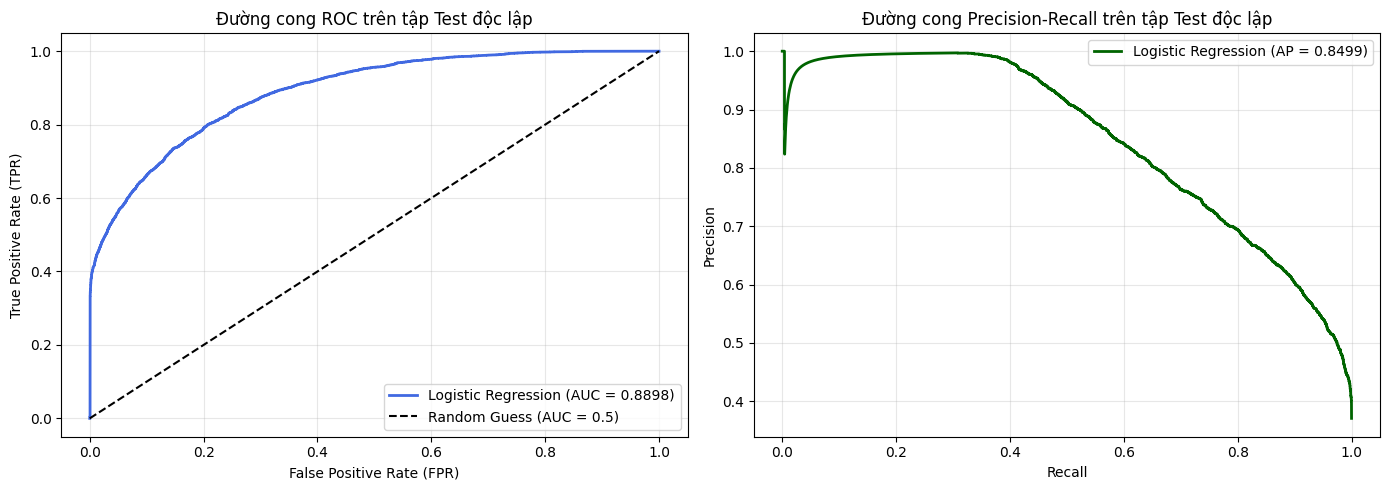

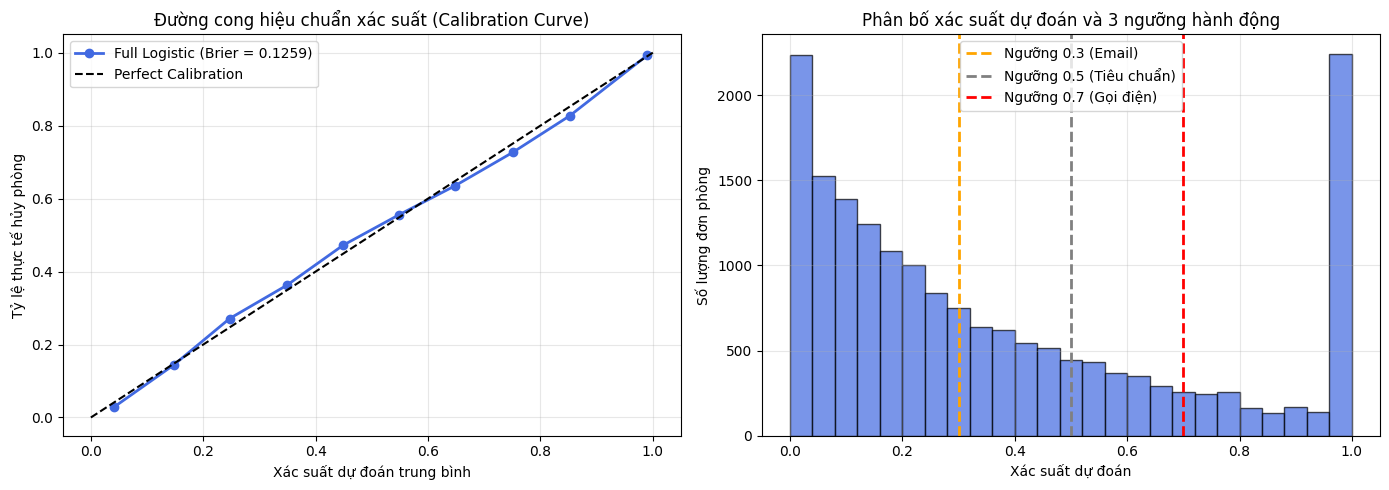

In [11]:
# ==============================================================================
# BƯỚC 9: KẾT LUẬN HIỆU NĂNG TRÊN TẬP TEST ĐỘC LẬP & LƯU HÌNH ẢNH ARTIFACT
# Tuân thủ: Tập Test chỉ chạy đúng 1 lần duy nhất ở bước cuối cùng!
# ==============================================================================
y_test_pred_prob = full_lr_pipeline.predict_proba(X_test)[:, 1]
y_test_pred_label = full_lr_pipeline.predict(X_test)

test_auc = roc_auc_score(y_test, y_test_pred_prob)
test_ap = average_precision_score(y_test, y_test_pred_prob)
test_logloss = log_loss(y_test, y_test_pred_prob)
test_brier = brier_score_loss(y_test, y_test_pred_prob)

print(f"=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ĐỘC LẬP (N = {len(y_test)}) ===")
print(f"1. ROC-AUC: {test_auc:.4f}")
print(f"2. PR-AUC (Average Precision): {test_ap:.4f}")
print(f"3. Log Loss: {test_logloss:.4f}")
print(f"4. Brier Score: {test_brier:.4f}")

# Tạo thư mục xuất ảnh cho Web và Báo cáo
os.makedirs("reports/figures", exist_ok=True)
os.makedirs("app/static", exist_ok=True)

# 1. Vẽ đồ thị ROC và PR trên tập Test
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fpr, tpr, _ = roc_curve(y_test, y_test_pred_prob)
axes[0].plot(fpr, tpr, color='royalblue', lw=2, label=f'Logistic Regression (AUC = {test_auc:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guess (AUC = 0.5)')
axes[0].set_title('Đường cong ROC trên tập Test độc lập')
axes[0].set_xlabel('False Positive Rate (FPR)')
axes[0].set_ylabel('True Positive Rate (TPR)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

precision_vals, recall_vals, _ = precision_recall_curve(y_test, y_test_pred_prob)
axes[1].plot(recall_vals, precision_vals, color='darkgreen', lw=2, label=f'Logistic Regression (AP = {test_ap:.4f})')
axes[1].set_title('Đường cong Precision-Recall trên tập Test độc lập')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("reports/figures/roc_pr_test_curves.png", dpi=300)
plt.savefig("app/static/roc_pr_test_curves.png", dpi=300)
plt.show()

# 2. Vẽ đường cong hiệu chuẩn Calibration và biểu đồ phân bố xác suất
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
prob_true, prob_pred = calibration_curve(y_test, y_test_pred_prob, n_bins=10)
axes[0].plot(prob_pred, prob_true, marker='o', lw=2, color='royalblue', label=f'Full Logistic (Brier = {test_brier:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5, label='Perfect Calibration')
axes[0].set_title('Đường cong hiệu chuẩn xác suất (Calibration Curve)')
axes[0].set_xlabel('Xác suất dự đoán trung bình')
axes[0].set_ylabel('Tỷ lệ thực tế hủy phòng')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].hist(y_test_pred_prob, bins=25, color='royalblue', edgecolor='black', alpha=0.7)
axes[1].axvline(0.3, color='orange', linestyle='--', lw=2, label='Ngưỡng 0.3 (Email)')
axes[1].axvline(0.5, color='gray', linestyle='--', lw=2, label='Ngưỡng 0.5 (Tiêu chuẩn)')
axes[1].axvline(0.7, color='red', linestyle='--', lw=2, label='Ngưỡng 0.7 (Gọi điện)')
axes[1].set_title('Phân bố xác suất dự đoán và 3 ngưỡng hành động')
axes[1].set_xlabel('Xác suất dự đoán')
axes[1].set_ylabel('Số lượng đơn phòng')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("reports/figures/calibration_and_distribution.png", dpi=300)
plt.savefig("app/static/calibration_and_distribution.png", dpi=300)
plt.show()

# **Bước 10 — Đóng gói Artifacts mô hình và xuất tệp**

In [13]:
# ==============================================================================
# BƯỚC 10: XUẤT ARTIFACT TRIỂN KHAI CHO FASTAPI VÀ BÁO CÁO KỸ THUẬT
# ==============================================================================
os.makedirs("models", exist_ok=True)

# 1. Lưu pipeline mô hình huấn luyện
MODEL_FILE = "models/logistic_pipeline.pkl"
joblib.dump(full_lr_pipeline, MODEL_FILE)

# 2. Lưu tệp cấu hình miền giá trị thực tế của dataset
BOUNDS_FILE = "models/domain_bounds.json"
with open(BOUNDS_FILE, "w", encoding="utf-8") as f:
    json.dump(domain_bounds, f, indent=4, ensure_ascii=False)

print("=== ĐÃ HOÀN TẤT VÀ XUẤT TOÀN BỘ ARTIFACTS ===")
print(f"1. Mô hình hoàn chỉnh: '{MODEL_FILE}'")
print(f"2. Tệp miền dữ liệu   : '{BOUNDS_FILE}'")
print(f"3. Hình ảnh đồ thị ROC : 'app/static/roc_pr_test_curves.png'")
print(f"4. Hình ảnh hiệu chuẩn : 'app/static/calibration_and_distribution.png'")

=== ĐÃ HOÀN TẤT VÀ XUẤT TOÀN BỘ ARTIFACTS ===
1. Mô hình hoàn chỉnh: 'models/logistic_pipeline.pkl'
2. Tệp miền dữ liệu   : 'models/domain_bounds.json'
3. Hình ảnh đồ thị ROC : 'app/static/roc_pr_test_curves.png'
4. Hình ảnh hiệu chuẩn : 'app/static/calibration_and_distribution.png'


In [14]:
from google.colab import files

# Tải 2 tệp cốt lõi cho mô hình và chốt chặn OOD
files.download('models/logistic_pipeline.pkl')
files.download('models/domain_bounds.json')

# Tải 2 ảnh đồ thị cho Web và Báo cáo
files.download('app/static/roc_pr_test_curves.png')
files.download('app/static/calibration_and_distribution.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>